# Klasifikasi II (Random Forest)

**Random Forest** adalah model *ensemble* yang terdiri dari banyak **Decision Tree** (pohon keputusan). Satu pohon bekerja seperti diagram alur "jika-maka", mudah dipahami tetapi gampang *overfitting* (terlalu "menghafal" data latih).

Random Forest mengatasinya dengan membangun banyak pohon, dan kuncinya ada pada kata **"Random"**:
- **Data acak (bagging)**: tiap pohon dilatih dari sampel acak data latih.
- **Fitur acak**: di tiap pemisahan, pohon hanya mempertimbangkan sebagian kecil fitur yang dipilih acak.

Prediksi akhir untuk klasifikasi adalah hasil **voting** semua pohon. Dua hal khas Random Forest yang dipelajari di sini: **hyperparameter tuning** (`n_estimators`, `max_depth`) dan **feature importance**.

---
## 1. Persiapan Environment & Import Library

### 1.1 Install Library

In [ ]:
#pip install pandas numpy matplotlib seaborn scikit-learn

### 1.2 Import Library yang Dibutuhkan

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

### 1.3 Mengenal Dataset Iris

Dataset **Iris** bawaan scikit-learn: 150 data panjang dan lebar sepal serta petal dari tiga jenis bunga Iris.

In [2]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='species')
print(X.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


---
## 2. Membagi Data Latih dan Data Uji

Bagi dataset menjadi 80% data latih dan 20% data uji (`random_state=42`).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
test_size=0.2, random_state=42)

---
## 3. Melatih Model Random Forest

Inisialisasi `RandomForestClassifier` dengan `n_estimators=100`, `max_depth=5`, `criterion='gini'`, dan `random_state=42`, lalu latih dengan `.fit()`.

In [4]:
model_rf = RandomForestClassifier(
n_estimators=100,
max_depth=5,
criterion='gini',
random_state=42
)
model_rf.fit(X_train, y_train)
print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.


---
## 4. Evaluasi Model

Prediksi data uji lalu tampilkan `classification_report`.

In [6]:
y_pred = model_rf.predict(X_test)
print("\nClassification Report")
print(classification_report(y_test,y_pred,target_names=iris.target_names))



Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



---
## 5. Analisis Feature Importance

Ekstrak `feature_importances_` dari model, buat tabel `Feature` dan `Importance`, lalu urutkan dari yang tertinggi.

In [7]:
importances = model_rf.feature_importances_
feature_importance_df = pd.DataFrame({
'Feature': iris.feature_names,
'Importance': importances
}).sort_values(
by='Importance',
ascending=False
)
print("\nTingkat Kepentingan Fitur (Feature Importance)")
print(feature_importance_df)


Tingkat Kepentingan Fitur (Feature Importance)
             Feature  Importance
2  petal length (cm)    0.445257
3   petal width (cm)    0.420793
0  sepal length (cm)    0.105913
1   sepal width (cm)    0.028037


---
## 6. Visualisasi Feature Importance

Buat barplot feature importance dengan Seaborn.

C:\Users\advan\AppData\Local\Temp\ipykernel_3588\3281514237.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


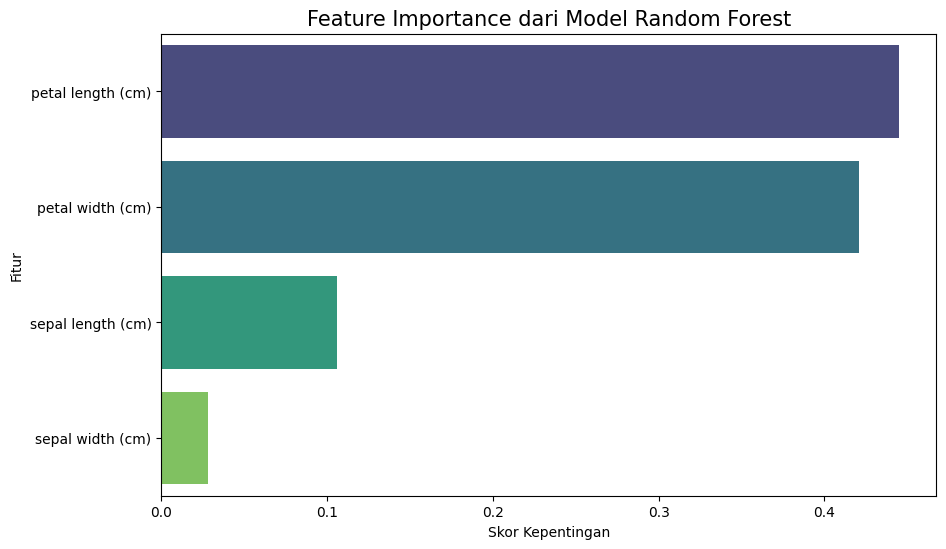

In [8]:
plt.figure(figsize=(10, 6))
sns.barplot(
x='Importance',
y='Feature',
data=feature_importance_df,
palette='viridis'
)
plt.title('Feature Importance dari Model Random Forest',
fontsize=15)
plt.xlabel('Skor Kepentingan')
plt.ylabel('Fitur')
plt.show()

---
## 7. Catatan Penting Praktikum

- Random Forest = banyak pohon + data acak (bagging) + fitur acak; prediksi lewat voting.
- Random Forest tidak sensitif skala fitur, sehingga scaling umumnya tidak perlu.
- `feature_importances_` adalah proporsi relatif (jumlah = 1), bukan akurasi.
- Satu skor dari satu split tidak cukup untuk menilai model.

---
## 8. Latihan

**Studi Kasus: Klasifikasi Jenis Wine Berdasarkan Analisis Kimia**

Dataset: gunakan dataset `wine` yang tersedia di scikit-learn (`sklearn.datasets.load_wine`).

Seorang data scientist bekerja untuk sebuah perkebunan anggur ternama. Perkebunan ini menghasilkan tiga jenis wine berbeda yang berasal dari kultivar anggur yang sama namun ditanam di area yang berbeda. Tim produksi ingin memahami secara ilmiah senyawa kimia apa yang paling signifikan dalam membedakan ketiga jenis wine ini. Informasi ini akan digunakan untuk standarisasi proses kontrol kualitas dan memastikan setiap jenis wine memiliki karakteristik kimia yang konsisten. Dataset berisi 13 hasil analisis kimia (fitur) dari 3 jenis wine (target).

Dengan menggunakan algoritma Random Forest, lakukan analisis berikut:
1. **Muat dan Eksplorasi Data**
   - Baca dataset wine dari `sklearn.datasets` dan ubah menjadi DataFrame pandas.
   - Tampilkan 10 baris terakhir.
   - *Tips:* jadikan target sebagai `pd.Series` (bukan DataFrame satu kolom) agar tidak muncul `DataConversionWarning` saat `fit`.
2. **Persiapan Data**
   - Definisikan X sebagai fitur (data kimia) dan y sebagai target (jenis wine).
   - Bagi dataset menjadi data latih (80%) dan data uji (20%). Gunakan `random_state=42`. (NB: boleh diubah jika skor akhir lebih baik.)
3. **Latih Model Random Forest**
   - Inisialisasi dan latih model `RandomForestClassifier` pada data latih. Bisa digunakan `n_estimators=100`.
4. **Evaluasi Kinerja Model**
   - Buat prediksi pada data uji dan cetak `classification_report` untuk melihat akurasi, presisi, dan recall model.
5. **Analisis Feature Importance**
   - Ekstrak skor kepentingan fitur (feature importance) dari model yang telah dilatih.
6. **Visualisasikan Hasil**
   - Buat bar plot menggunakan seaborn untuk memvisualisasikan skor feature importance. Urutkan fitur dari yang paling penting hingga yang kurang penting.
7. **Interpretasi dan Rekomendasi**
   - Berdasarkan visualisasi, tiga senyawa kimia apa yang menjadi pembeda utama antar jenis wine?
   - Jika tim produksi ingin melakukan tes kontrol kualitas yang cepat dan hemat biaya dengan hanya mengukur beberapa fitur kunci, fitur mana saja yang sebaiknya direkomendasikan untuk diukur? Jelaskan alasannya.
   - Anggap fitur `proline` dan `flavanoids` memiliki skor tertinggi. Apa artinya ini bagi seorang ahli wine dalam konteks identifikasi produk?

NB: Jawab pertanyaan nomor 7 dalam teks markdown.

In [18]:
import pandas as pd
from sklearn.datasets import load_wine

# Memuat dataset wine
wine = load_wine()

# Mengubah dataset menjadi DataFrame
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.DataFrame(wine.target, columns=['target'])

# Menampilkan 10 baris terakhir
print("10 Baris Terakhir Data Fitur:")
display(X.tail(10))

print("10 Baris Terakhir Target:")
display(y.tail(10))

# Informasi dataset
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)
print("Nama fitur:", wine.feature_names)
print("Nama kelas:", wine.target_names)

10 Baris Terakhir Data Fitur:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
168,13.58,2.58,2.69,24.5,105.0,1.55,0.84,0.39,1.54,8.660000,0.74,1.80,750.0
169,13.40,4.60,2.86,25.0,112.0,1.98,0.96,0.27,1.11,8.500000,0.67,1.92,630.0
170,12.20,3.03,2.32,19.0,96.0,1.25,0.49,0.40,0.73,5.500000,0.66,1.83,510.0
171,12.77,2.39,2.28,19.5,86.0,1.39,0.51,0.48,0.64,9.899999,0.57,1.63,470.0
172,14.16,2.51,2.48,20.0,91.0,1.68,0.70,0.44,1.24,9.700000,0.62,1.71,660.0
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.700000,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.300000,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.200000,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.300000,0.60,1.62,840.0
177,14.13,4.10,2.74,24.5,96.0,2.05,0.76,0.56,1.35,9.200000,0.61,1.60,560.0


10 Baris Terakhir Target:


,target
168,2
169,2
170,2
171,2
172,2
173,2
174,2
175,2
176,2
177,2


Ukuran X: (178, 13)
Ukuran y: (178, 1)
Nama fitur: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Nama kelas: ['class_0' 'class_1' 'class_2']


In [19]:
from sklearn.model_selection import train_test_split

# X = fitur kimia, y = target jenis wine
X_train, X_test, y_train, y_test = train_test_split(
    X, wine.target,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 142
Jumlah data uji: 36


In [20]:
from sklearn.ensemble import RandomForestClassifier

# Inisialisasi model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Melatih model
model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.
